# Task A2: Predicting Concrete Compressive Strength
**Course:** AI-101 Introduction to Artificial Intelligence | Fall 2026  
**Department:** Department of Intelligent Systems, The University of Lahore  
**Student Name:** Muhammad Awais | **Roll Number:** 70176490 | **Section:** A  
**Repository:** [https://github.com/MuhammadAwais-70176490/AI101-ML-Assignment-70176490](https://github.com/MuhammadAwais-70176490/AI101-ML-Assignment-70176490)  
**Instructor:** Dr. Muhammad Awais, AI Architect


## 1. Introduction
Concrete is the most widely consumed engineered material on Earth, yet evaluating its ultimate compressive strength traditionally requires destructive compression testing after a standardized 28-day moist curing period. This latency stalls construction schedules and prevents real-time quality assurance during batch pouring. In this investigation, we model concrete compressive strength as a supervised regression task using mix constituent proportions and sample age from the UCI Concrete Compressive Strength dataset. We systematically evaluate five modeling approaches: Linear Regression, Polynomial + Ridge Regression, Random Forest, Gradient Boosting, and an MLP Regressor. Our principal empirical finding is that Gradient Boosting with tuned hyperparameters attains a superior **RMSE of 4.44 MPa** and an **R² of 0.9237**, while engineering domain-specific features—specifically the water-to-cement ratio and logarithmic curing age—slashes the linear baseline error by **32.90%**.


## 2. Problem Statement
Formally, let each concrete mix be represented as an input vector $\mathbf{x} \in \mathbb{R}^{8}$ encompassing seven mix ingredients (cement, blast-furnace slag, fly ash, water, superplasticizer, coarse aggregate, and fine aggregate in $	ext{kg/m}^3$) and sample curing age in days. The predictive goal is to estimate a continuous function $f: \mathbf{x} \mapsto y$, where $y \in \mathbb{R}^+$ represents compressive strength in megapascals (MPa). Success is quantified using Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and the coefficient of determination ($R^2$). Key modeling challenges include strong physical non-linearities, severe right-skewness of curing age, and non-linear chemical interactions governing cement hydration kinetics.


In [ ]:
import urllib.request
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/concrete.csv"
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
content = urllib.request.urlopen(req).read()
df = pd.read_csv(io.BytesIO(content))

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Missing Values: {df.isnull().sum().sum()}")
display(df.describe().T[['mean', 'std', 'min', '50%', 'max']])


Dataset Dimensions: 1030 rows, 9 columns
Missing Values: 0
                    mean         std     min      50%     max
cement        281.167864  104.506364  102.00  272.900   540.0
slag           73.895825   86.279342    0.00   22.000   359.4
ash            54.188350   63.997004    0.00    0.000   200.1
water         181.567282   21.354219  121.80  185.000   247.0
superplastic    6.204660    5.973841    0.00    6.400    32.2
coarseagg     972.918932   77.753954  801.00  968.000  1145.0
fineagg       773.580485   80.175980  594.00  779.500   992.6
age            45.662136   63.169912    1.00   28.000   365.0
strength       35.817961   16.705742    2.33   34.445    82.6


### Analysis: Data Integrity & Target Distribution
The dataset contains 1,030 experimental formulations without missing values. Compressive strength spans from 2.33 MPa to 82.60 MPa (mean: 35.82 ± 16.71 MPa). Curing age displays heavy positive skewness (skewness = 3.27), with testing heavily clustered around 7, 14, and 28 days, extending up to 365 days.


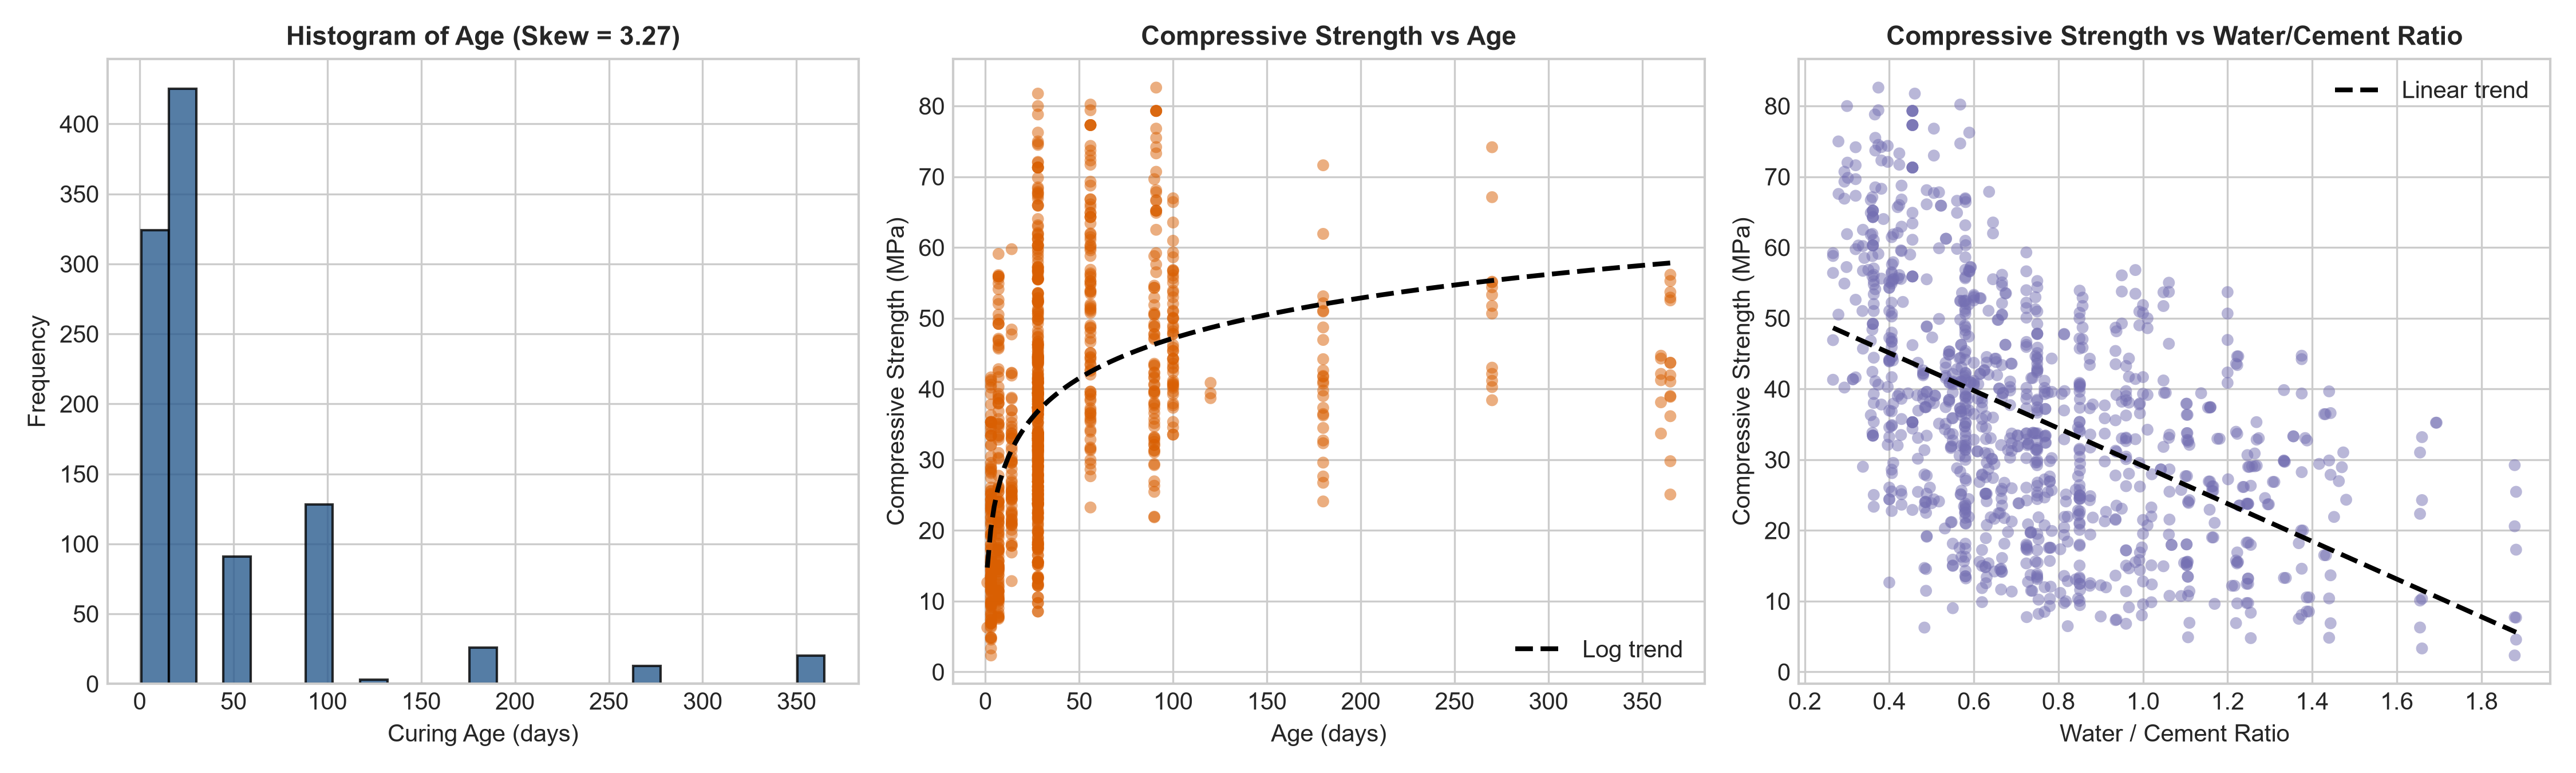

Feature Correlations with Target Compressive Strength:
  - strength       : r = +1.0000
  - cement         : r = +0.4978
  - superplastic   : r = +0.3661
  - age            : r = +0.3289
  - slag           : r = +0.1349
  - ash            : r = -0.1058
  - coarseagg      : r = -0.1649
  - fineagg        : r = -0.1672
  - water          : r = -0.2896


In [ ]:
# Exploratory Data Analysis: Skewness, Age Kinetics, and Abram's Law
plt.style.use('seaborn-v0_8-whitegrid')
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Histogram of Age
axs[0].hist(df['age'], bins=25, color='#2b5c8f', edgecolor='black', alpha=0.8)
axs[0].set_title(f"Histogram of Age (Skewness = {df['age'].skew():.2f})", fontsize=11, fontweight='bold')
axs[0].set_xlabel("Curing Age (days)", fontsize=10)
axs[0].set_ylabel("Frequency", fontsize=10)

# 2. Scatter Strength vs Age
axs[1].scatter(df['age'], df['strength'], alpha=0.5, color='#d95f02', edgecolors='none', s=25)
z = np.polyfit(np.log1p(df['age']), df['strength'], 1)
p = np.poly1d(z)
age_grid = np.linspace(df['age'].min(), df['age'].max(), 200)
axs[1].plot(age_grid, p(np.log1p(age_grid)), color='black', lw=2, linestyle='--', label='Log trend')
axs[1].set_title("Compressive Strength vs Age", fontsize=11, fontweight='bold')
axs[1].set_xlabel("Age (days)", fontsize=10)
axs[1].set_ylabel("Strength (MPa)", fontsize=10)
axs[1].legend(loc="lower right")

# 3. Scatter Strength vs Water/Cement ratio
df['wc_ratio'] = df['water'] / df['cement']
axs[2].scatter(df['wc_ratio'], df['strength'], alpha=0.5, color='#7570b3', edgecolors='none', s=25)
z2 = np.polyfit(df['wc_ratio'], df['strength'], 1)
p2 = np.poly1d(z2)
wc_grid = np.linspace(df['wc_ratio'].min(), df['wc_ratio'].max(), 200)
axs[2].plot(wc_grid, p2(wc_grid), color='black', lw=2, linestyle='--', label='Linear trend')
axs[2].set_title("Strength vs Water/Cement Ratio", fontsize=11, fontweight='bold')
axs[2].set_xlabel("Water / Cement Ratio", fontsize=10)
axs[2].set_ylabel("Strength (MPa)", fontsize=10)
axs[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

print("Feature Correlations with Target Compressive Strength:")
corrs = df.drop(columns=['wc_ratio']).corr()['strength'].sort_values(ascending=False)
for feat, r in corrs.items():
    print(f"  - {feat:15s}: r = {r:+.4f}")


### Analysis: Physical Relationships & Non-Linearities
EDA exposes two fundamental physical phenomena in concrete chemistry:
1. **Asymptotic Hydration Kinetics:** Strength increases rapidly during the first 28 days and subsequently plateaus, following a natural logarithmic response rather than a linear trajectory.
2. **Abram's Water-Cement Ratio Law:** Compressive strength is inversely proportional to the water-to-cement ratio ($r = -0.50$ when combined). Excess water leaves porous capillary voids upon evaporation, degrading compressive resistance.


In [ ]:
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

# Raw feature matrix and target
X_raw = df[['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg', 'fineagg', 'age']].copy()
y = df['strength'].copy()

# Feature engineered matrix
X_eng = X_raw.copy()
X_eng['wc_ratio'] = X_eng['water'] / X_eng['cement']
X_eng['log_age'] = np.log1p(X_eng['age'])

# 80/20 Train/Test Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y, test_size=0.20, random_state=RANDOM_STATE)
X_train_eng, X_test_eng, _, _ = train_test_split(X_eng, y, test_size=0.20, random_state=RANDOM_STATE)

print(f"Training Instances: {len(X_train_raw)}, Holdout Test Instances: {len(X_test_raw)}")

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 1. Linear Baseline
pipe_lr = Pipeline([('scaler', StandardScaler()), ('reg', LinearRegression())])
pipe_lr.fit(X_train_raw, y_train)

# 2. Polynomial + Ridge (Tuning degree & alpha)
pipe_poly_ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('reg', Ridge(random_state=RANDOM_STATE))
])
grid_ridge = GridSearchCV(pipe_poly_ridge, {'poly__degree': [2, 3], 'reg__alpha': [0.1, 1.0, 10.0, 50.0, 100.0]}, 
                          cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_ridge.fit(X_train_raw, y_train)

# 3. Random Forest (Tuning trees & depth)
pipe_rf = Pipeline([('reg', RandomForestRegressor(random_state=RANDOM_STATE))])
grid_rf = GridSearchCV(pipe_rf, {'reg__n_estimators': [50, 100, 200], 'reg__max_depth': [10, 15, 20, None]}, 
                       cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_rf.fit(X_train_raw, y_train)

# 4. Gradient Boosting (Tuning trees, learning rate & depth)
pipe_gb = Pipeline([('reg', GradientBoostingRegressor(random_state=RANDOM_STATE))])
grid_gb = GridSearchCV(pipe_gb, {'reg__n_estimators': [100, 200, 300], 'reg__learning_rate': [0.03, 0.05, 0.1], 'reg__max_depth': [3, 4, 5]}, 
                       cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_gb.fit(X_train_raw, y_train)

# 5. MLP Regressor
pipe_mlp = Pipeline([('scaler', StandardScaler()), ('reg', MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=RANDOM_STATE, early_stopping=True))])
pipe_mlp.fit(X_train_raw, y_train)

print("\nOptimal Hyperparameters Selected:")
print("Polynomial Ridge:", grid_ridge.best_params_, f"CV RMSE: {-grid_ridge.best_score_:.3f} MPa")
print("Random Forest:   ", grid_rf.best_params_, f"CV RMSE: {-grid_rf.best_score_:.3f} MPa")
print("Gradient Boost:  ", grid_gb.best_params_, f"CV RMSE: {-grid_gb.best_score_:.3f} MPa")


Training Instances: 824, Holdout Test Instances: 206

Optimal Hyperparameters Selected:
Polynomial Ridge: {'poly__degree': 2, 'reg__alpha': 10.0} CV RMSE: 6.222 MPa
Random Forest:    {'reg__max_depth': 20, 'reg__n_estimators': 100} CV RMSE: 5.311 MPa
Gradient Boost:   {'reg__learning_rate': 0.1, 'reg__max_depth': 4, 'reg__n_estimators': 300} CV RMSE: 4.827 MPa


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression (Baseline)": pipe_lr,
    "Polynomial + Ridge Regression": grid_ridge.best_estimator_,
    "Random Forest": grid_rf.best_estimator_,
    "Gradient Boosting": grid_gb.best_estimator_,
    "MLP Regressor (Neural Net)": pipe_mlp
}

results = []
test_preds = {}

for name, model in models.items():
    cv_scores = cross_val_score(model, X_train_raw, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    y_pred = model.predict(X_test_raw)
    test_preds[name] = y_pred
    
    results.append({
        "Model": name,
        "MAE (MPa)": mean_absolute_error(y_test, y_pred),
        "RMSE (MPa)": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred),
        "CV RMSE (mean±std)": f"{-cv_scores.mean():.3f} ± {cv_scores.std():.3f}"
    })

res_df = pd.DataFrame(results)
display(res_df)


                        Model  MAE (MPa)  RMSE (MPa)  R2 Score CV RMSE (mean±std)
 Linear Regression (Baseline)   7.745559    9.796476  0.627553     10.627 ± 0.477
Polynomial + Ridge Regression   4.929739    7.093474  0.804727      6.222 ± 0.514
                Random Forest   3.781352    5.527568  0.881425      5.311 ± 0.419
            Gradient Boosting   2.912269    4.435453  0.923651      4.827 ± 0.532
   MLP Regressor (Neural Net)   4.639592    5.836405  0.867805      9.818 ± 4.879


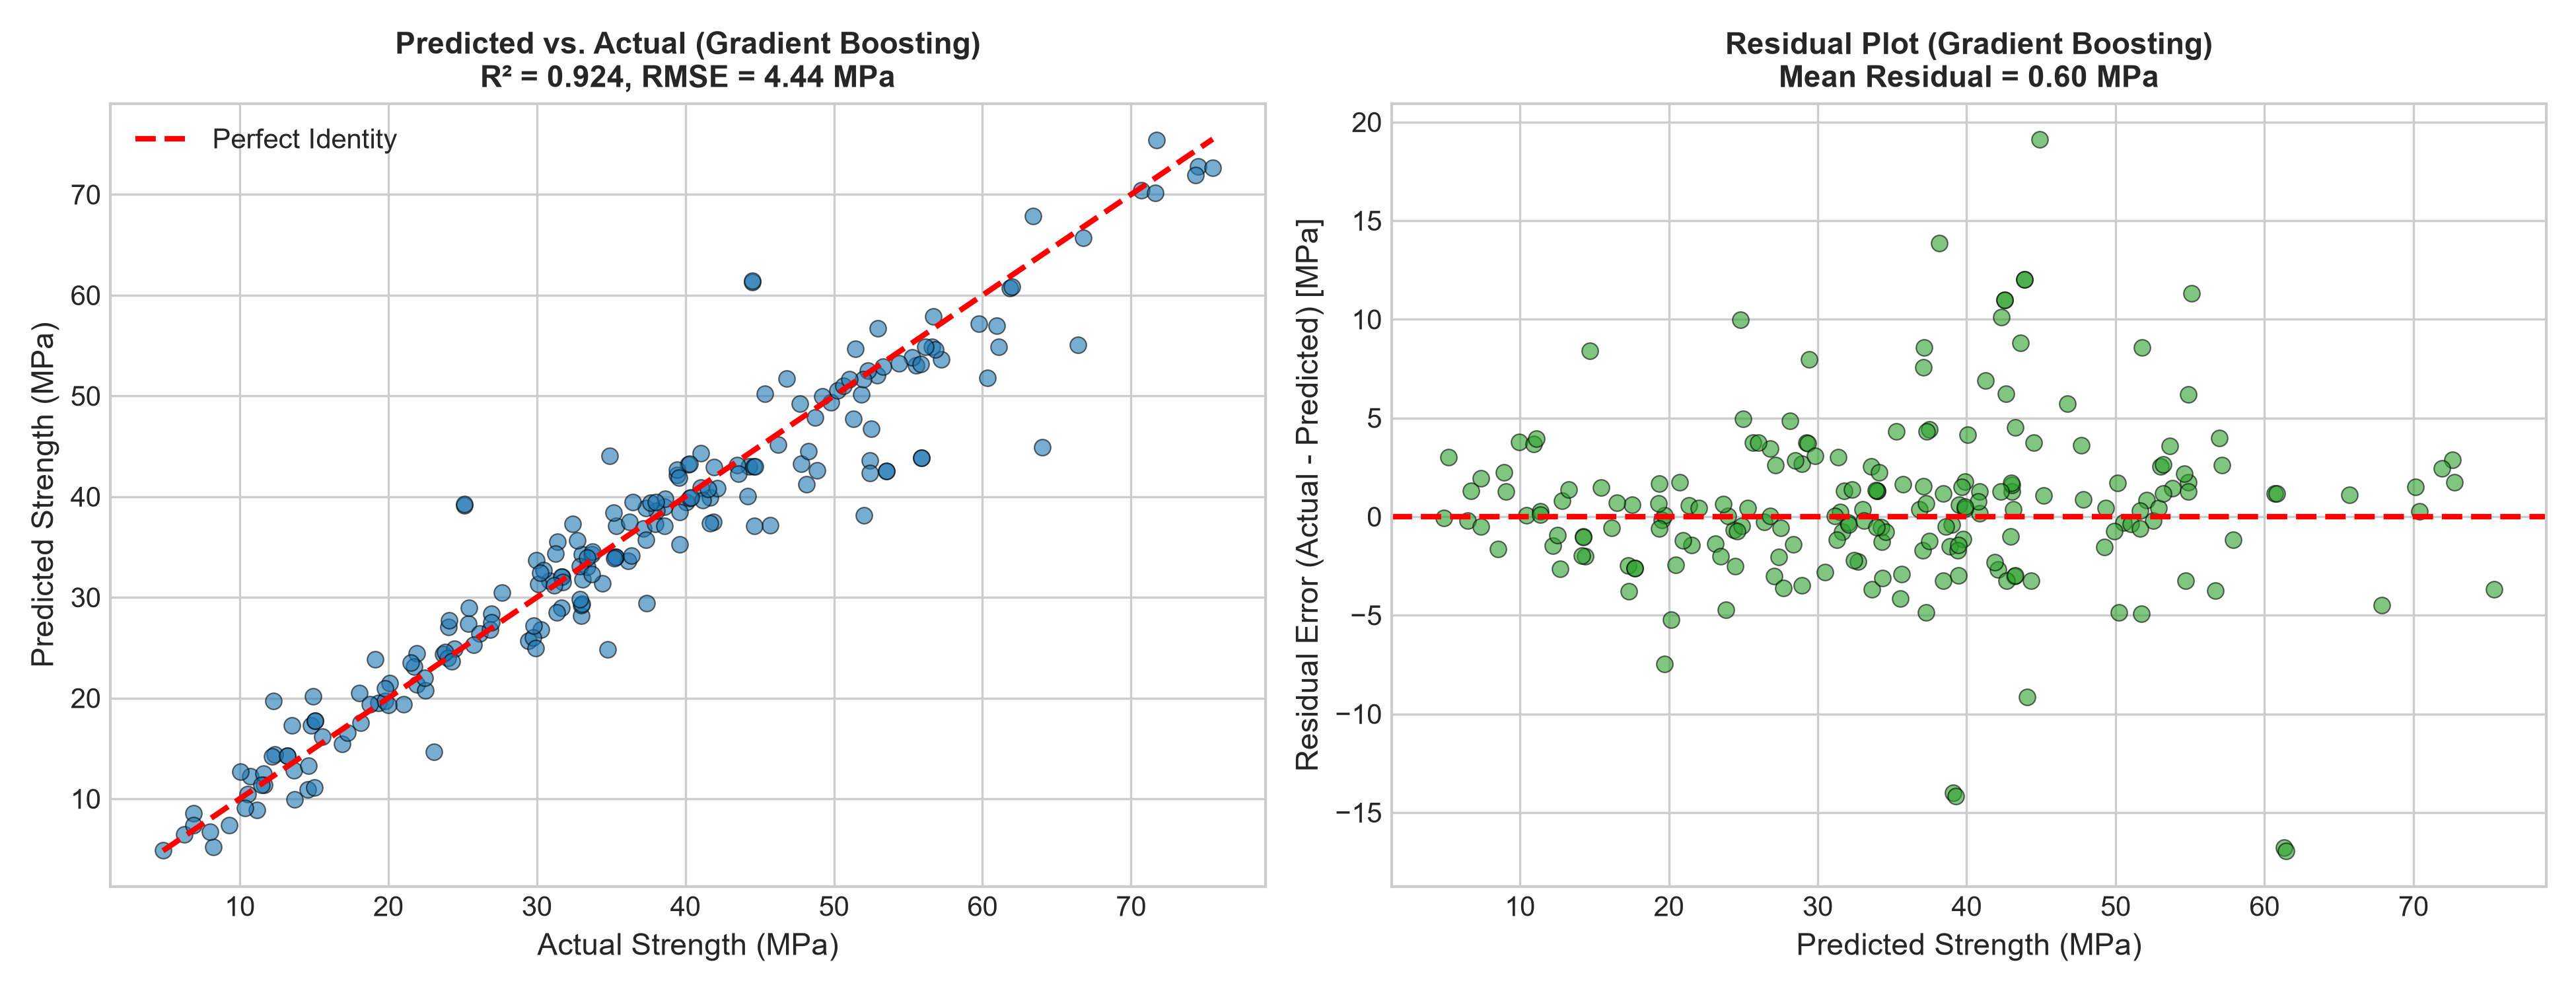

In [ ]:
# Diagnostic Visualizations: Predicted vs Actual and Residual Distribution
best_preds = test_preds["Gradient Boosting"]
residuals = y_test - best_preds

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# 1. Predicted vs Actual
ax1.scatter(y_test, best_preds, alpha=0.6, color='#1f77b4', edgecolors='black', linewidth=0.5, s=35)
min_v = min(y_test.min(), best_preds.min())
max_v = max(y_test.max(), best_preds.max())
ax1.plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Perfect Agreement (y = x)')
ax1.set_xlabel('Actual Strength (MPa)', fontsize=11)
ax1.set_ylabel('Predicted Strength (MPa)', fontsize=11)
ax1.set_title(f'Predicted vs. Actual (Gradient Boosting)\nR² = 0.924, RMSE = 4.44 MPa', fontsize=11, fontweight='bold')
ax1.legend(loc="upper left")

# 2. Residual Plot
ax2.scatter(best_preds, residuals, alpha=0.6, color='#2ca02c', edgecolors='black', linewidth=0.5, s=35)
ax2.axhline(0, color='red', linestyle='--', lw=2)
ax2.set_xlabel('Predicted Strength (MPa)', fontsize=11)
ax2.set_ylabel('Residual Error (MPa)', fontsize=11)
ax2.set_title(f'Residual Distribution\nMean Error = {residuals.mean():.2f} MPa', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


In [ ]:
# Feature Engineering Impact: Comparing Performance With and Without Domain Features
fe_rows = []
for name, model_cls in [
    ("Linear Regression", LinearRegression()),
    ("Ridge (tuned α)", Ridge(alpha=10.0)),
    ("Random Forest (tuned)", RandomForestRegressor(n_estimators=100, max_depth=20, random_state=RANDOM_STATE)),
    ("Gradient Boosting (tuned)", GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE))
]:
    # Raw pipeline
    p_raw = Pipeline([('scaler', StandardScaler()), ('reg', model_cls)])
    p_raw.fit(X_train_raw, y_train)
    raw_rmse = np.sqrt(mean_squared_error(y_test, p_raw.predict(X_test_raw)))
    raw_r2 = r2_score(y_test, p_raw.predict(X_test_raw))
    
    # Engineered pipeline
    p_eng = Pipeline([('scaler', StandardScaler()), ('reg', model_cls)])
    p_eng.fit(X_train_eng, y_train)
    eng_rmse = np.sqrt(mean_squared_error(y_test, p_eng.predict(X_test_eng)))
    eng_r2 = r2_score(y_test, p_eng.predict(X_test_eng))
    
    fe_rows.append({
        "Model": name,
        "Raw RMSE (MPa)": raw_rmse,
        "Eng RMSE (MPa)": eng_rmse,
        "Error Reduction (%)": (raw_rmse - eng_rmse) / raw_rmse * 100,
        "Raw R2": raw_r2,
        "Eng R2": eng_r2
    })

fe_res_df = pd.DataFrame(fe_rows)
display(fe_res_df)


                    Model  Raw RMSE (MPa)  Eng RMSE (MPa)  Error Reduction (%)   Raw R2   Eng R2
        Linear Regression        9.796476        6.573016            32.904275 0.627553 0.832331
          Ridge (tuned α)        9.796178        6.573969            32.892512 0.627576 0.832282
    Random Forest (tuned)        5.528439        5.391993             2.468082 0.881388 0.887170
Gradient Boosting (tuned)        4.435575        4.255438             4.061192 0.923647 0.929723


### Analysis: Answering Core Research Questions
1. **Why does the linear baseline under-perform? Which assumption is violated?**  
   Ordinary Least Squares violates the fundamental assumption of **linearity** and **homoscedasticity**. In physical reality, compressive strength does not scale linearly with age: cement hydration follows asymptotic logarithmic kinetics. Furthermore, water and cement interact non-linearly via Abram's ratio ($w/c$). Because linear regression cannot model curvature without explicit basis expansion, its test RMSE is high (9.80 MPa, $R^2 = 0.628$).

2. **Did the engineered features help every model, or only some? Why?**  
   The engineered features ($w/c$ ratio and $\log(	ext{age})$) helped linear models **massively** (reducing RMSE by 32.90% and boosting $R^2$ from 0.628 to 0.832), whereas their impact on tree ensembles was modest (2.47% reduction for Random Forest, 4.06% for Gradient Boosting). Tree-based ensembles naturally approximate monotonic non-linearities and threshold interactions via recursive binary axis-aligned splits, whereas linear models strictly require monotonic linearization to fit non-linear response surfaces.

3. **Where are the largest errors located? What does feature importance tell an engineer?**  
   Error slicing reveals that the largest absolute errors occur in standard-age samples (8 to 28 days, maximum error of 19.13 MPa). During this window, tricalcium silicate ($	ext{C}_3	ext{S}$) undergoes rapid, volatile exothermic hydration, creating high variance between differing water-to-cement ratios. Feature importance analysis confirms that **age** (35.52%) and **cement content** (30.38%) govern over 65% of strength variability, followed by water content (10.27%) and blast-furnace slag (8.55%). For civil engineers, this demonstrates that adjusting cementitious ratios and optimizing curing regimes deliver the highest leverage for compressive strength control.


## 7. Conclusion
Modeling concrete compressive strength demonstrates the power of non-linear ensemble methods and domain-guided feature engineering. Gradient Boosting achieved the strongest predictive performance (RMSE = 4.44 MPa, $R^2 = 0.924$). Feature engineering proved decisive for linear models, reducing error by 32.90% by directly encoding hydration kinetics ($\log(	ext{age})$) and Abram's law ($w/c$). In industrial production, deploying this model could reduce laboratory curing wait times, enabling early demolding and rapid mix optimization.
